In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")
from ingestion.mastr_turbines import IMPUTE_LEVELS, impute_coords

t = pd.read_parquet("../data/interim/turbines_stage1.parquet")
t["coord_source"] = t["coord_source"].fillna("not_filled")
imp = t[t["coord_source"] != "mastr"]

summary = imp.groupby("coord_source").agg(
    units=("unit_id", "count"),
    total_mw=("capacity_kw", lambda s: round(s.sum() / 1000, 1)),
    median_kw=("capacity_kw", "median"),
    max_kw=("capacity_kw", "max"),
)
print(summary, "\n")
print(pd.crosstab(imp["coord_source"], imp["location_type"]), "\n")
print(pd.crosstab(imp["coord_source"], imp["status"]))

print(IMPUTE_LEVELS[0])

                    units  total_mw  median_kw   max_kw
coord_source                                           
district_state        358      30.6      3.600  3200.00
municipality_state     58       0.3      2.125    30.00
not_filled             61       0.3      4.500    13.33
postcode              737       7.4      6.000  1500.00
wind_farm_district     12      19.1     22.500  5700.00 

location_type       onshore
coord_source               
district_state          358
municipality_state       58
not_filled               61
postcode                737
wind_farm_district       12 

status              decommissioned  operating  temporarily_shut_down
coord_source                                                        
district_state                  42        305                     11
municipality_state              11         45                      2
not_filled                      13         47                      1
postcode                        67        653                  

In [2]:
cols = [
    "coord_source",
    "state",
    "postcode",
    "municipality",
    "wind_farm",
    "capacity_kw",
    "lon",
    "lat",
]
imp.groupby("coord_source").head(3)[cols]

,coord_source,state,postcode,municipality,wind_farm,capacity_kw,lon,lat
36,postcode,Schleswig-Holstein,25853,Ahrenshöft,Dahl nach der meede,6.0,9.070525,54.583473
76,postcode,Niedersachsen,26169,Friesoythe,KWEA,29.8,7.770969,52.994131
94,postcode,Schleswig-Holstein,25873,Rantrum,PSW,10.0,9.158303,54.461995
122,district_state,Bayern,87488,Betzigau,NaN,1.0,10.434083,47.788947
253,district_state,Bayern,87480,Weitnau,WindKraft KHS,10.0,10.434083,47.788947
276,not_filled,Bayern,85435,Erding,NaN,5.5,NaN,NaN
499,district_state,Baden-Württemberg,72469,Meßstetten,Windrad,9.9,9.152572,48.368663
2431,not_filled,Bayern,91126,Schwabach,Windrad Stadtwerke,1.0,NaN,NaN
2542,wind_farm_district,Rheinland-Pfalz,54497,Monzelfeld,Energielandschaft Morbach,2000.0,7.104784,49.829171
6112,municipality_state,Nordrhein-Westfalen,47447,Moers,Astos 30,30.0,6.600225,51.515716


In [3]:
def distance_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = (
        np.sin((lat2 - lat1) / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    )
    return 6371 * 2 * np.arcsin(np.sqrt(a))


good = t[t["coord_source"] == "mastr"].copy()
hidden = good.sample(2000, random_state=0).index

test = good.copy()
test["true_lon"] = test["lon"]
test["true_lat"] = test["lat"]
test.loc[hidden, ["lon", "lat"]] = np.nan
test.loc[hidden, "coords_ok"] = False

res = impute_coords(test).loc[hidden]
res["error_km"] = distance_km(res["true_lat"], res["true_lon"], res["lat"], res["lon"])
res["coord_source"] = res["coord_source"].fillna("not_filled")

print(res.groupby("coord_source")["error_km"].describe().round(1))

                     count  mean   std   min   25%   50%   75%    max
coord_source                                                         
district_state        10.0  17.9  12.2   1.8   9.7  16.7  26.0   40.0
municipality_state     1.0  11.8   NaN  11.8  11.8  11.8  11.8   11.8
not_filled             0.0   NaN   NaN   NaN   NaN   NaN   NaN    NaN
postcode             393.0   5.0   8.7   0.0   0.9   2.8   5.9  107.3
wind_farm_district  1500.0   0.7   1.4   0.0   0.4   0.5   0.8   38.9


Text(0, 0.5, 'Latitude')

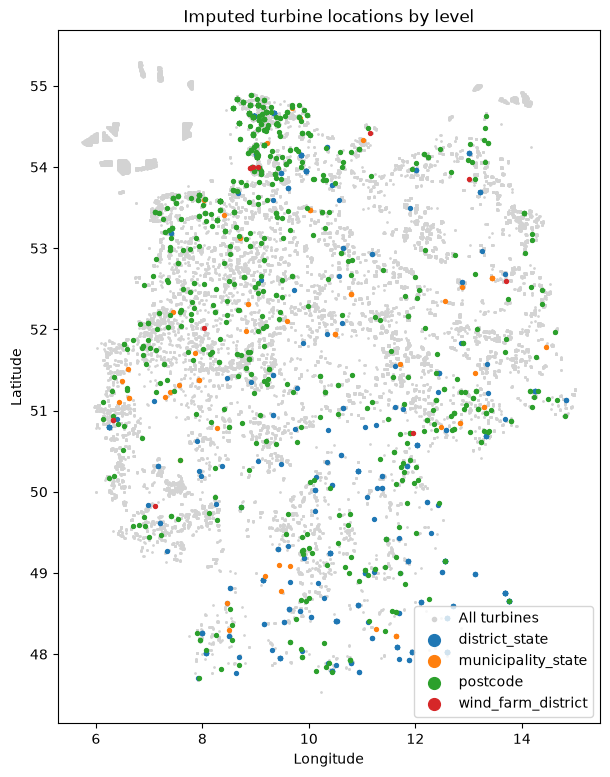

In [4]:
plt.figure(figsize=(7, 9))
plt.scatter(t["lon"], t["lat"], s=1, color="lightgrey", label="All turbines")
for level, d in imp[imp["coord_source"] != "not_filled"].groupby("coord_source"):
    plt.scatter(d["lon"], d["lat"], s=8, label=level)
plt.legend(markerscale=3)
plt.title("Imputed turbine locations by level")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

In [5]:
res.nlargest(5, "error_km")[
    [
        "unit_id",
        "state",
        "postcode",
        "municipality",
        "true_lon",
        "true_lat",
        "lon",
        "lat",
        "error_km",
        "capacity_kw",
    ]
]

,unit_id,state,postcode,municipality,true_lon,true_lat,lon,lat,error_km,capacity_kw
26025,SEE968122415198,Nordrhein-Westfalen,46325,Borken,6.000000,51.000000,6.879858,51.793270,107.267603,655.0
3764,SEE960989715879,Brandenburg,15913,Märkische Heide,13.581695,51.580267,14.074262,51.972673,55.247545,2000.0
25588,SEE962963785786,Brandenburg,16248,Lunow-Stolzenhagen,14.524220,52.559230,14.052450,52.947075,53.553257,600.0
12531,SEE936808217954,Sachsen-Anhalt,38838,Huy,11.656188,51.772993,11.016253,52.018133,51.683360,2300.0
4203,SEE924920819767,Sachsen-Anhalt,38855,Nordharz,10.891207,51.932237,10.540230,51.555460,48.364891,600.0
